In [30]:
import nltk
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('/content/Corona_NLP_train.csv',encoding='ISO-8859-1')
df

,UserName,ScreenName,Location,TweetAt,OriginalTweet,Sentiment
0,3799,48751,London,16-03-2020,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,3800,48752,UK,16-03-2020,advice Talk to your neighbours family to excha...,Positive
2,3801,48753,Vagabonds,16-03-2020,Coronavirus Australia: Woolworths to give elde...,Positive
3,3802,48754,NaN,16-03-2020,My food stock is not the only one which is emp...,Positive
4,3803,48755,NaN,16-03-2020,"Me, ready to go at supermarket during the #COV...",Extremely Negative
...,...,...,...,...,...,...
41152,44951,89903,"Wellington City, New Zealand",14-04-2020,Airline pilots offering to stock supermarket s...,Neutral
41153,44952,89904,NaN,14-04-2020,Response to complaint not provided citing COVI...,Extremely Negative
41154,44953,89905,NaN,14-04-2020,You know itÂs getting tough when @KameronWild...,Positive
41155,44954,89906,NaN,14-04-2020,Is it wrong that the smell of hand sanitizer i...,Neutral


In [31]:
#DATA UNDERSTANDING

#first 3 rows
print(df.head(3))

   UserName  ScreenName   Location     TweetAt  \
0      3799       48751     London  16-03-2020   
1      3800       48752         UK  16-03-2020   
2      3801       48753  Vagabonds  16-03-2020   

                                       OriginalTweet Sentiment  
0  @MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...   Neutral  
1  advice Talk to your neighbours family to excha...  Positive  
2  Coronavirus Australia: Woolworths to give elde...  Positive  


In [32]:
#last 3 rows
print(df.tail(3))

       UserName  ScreenName                      Location     TweetAt  \
41154     44953       89905                           NaN  14-04-2020   
41155     44954       89906                           NaN  14-04-2020   
41156     44955       89907  i love you so much || he/him  14-04-2020   

                                           OriginalTweet Sentiment  
41154  You know itÂs getting tough when @KameronWild...  Positive  
41155  Is it wrong that the smell of hand sanitizer i...   Neutral  
41156  @TartiiCat Well new/used Rift S are going for ...  Negative  


In [33]:
#number of rows and columns
print(df.shape)
#dimension
print(df.ndim)

(41157, 6)
2


In [34]:
#statistical summary
print(df.describe())

           UserName    ScreenName
count  41157.000000  41157.000000
mean   24377.000000  69329.000000
std    11881.146851  11881.146851
min     3799.000000  48751.000000
25%    14088.000000  59040.000000
50%    24377.000000  69329.000000
75%    34666.000000  79618.000000
max    44955.000000  89907.000000


In [35]:
#informations
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41157 entries, 0 to 41156
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   UserName       41157 non-null  int64 
 1   ScreenName     41157 non-null  int64 
 2   Location       32567 non-null  object
 3   TweetAt        41157 non-null  object
 4   OriginalTweet  41157 non-null  object
 5   Sentiment      41157 non-null  object
dtypes: int64(2), object(4)
memory usage: 1.9+ MB
None


In [36]:
#datatypes
print(df.dtypes)

UserName          int64
ScreenName        int64
Location         object
TweetAt          object
OriginalTweet    object
Sentiment        object
dtype: object


In [37]:
#column names
print(df.columns)

Index(['UserName', 'ScreenName', 'Location', 'TweetAt', 'OriginalTweet',
       'Sentiment'],
      dtype='object')


In [38]:
#number of unique values in each column
print(df.nunique())

UserName         41157
ScreenName       41157
Location         12220
TweetAt             30
OriginalTweet    41157
Sentiment            5
dtype: int64


In [39]:
#null values
print(df.isnull().sum())

UserName            0
ScreenName          0
Location         8590
TweetAt             0
OriginalTweet       0
Sentiment           0
dtype: int64


In [40]:
#duplicate values
print(df.duplicated().sum())

0


In [41]:
#DATA CLEANING

#dropping unwanted columns
df=df.drop(['UserName','ScreenName','Location','TweetAt'],axis=1)
df

,OriginalTweet,Sentiment
0,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,Neutral
1,advice Talk to your neighbours family to excha...,Positive
2,Coronavirus Australia: Woolworths to give elde...,Positive
3,My food stock is not the only one which is emp...,Positive
4,"Me, ready to go at supermarket during the #COV...",Extremely Negative
...,...,...
41152,Airline pilots offering to stock supermarket s...,Neutral
41153,Response to complaint not provided citing COVI...,Extremely Negative
41154,You know itÂs getting tough when @KameronWild...,Positive
41155,Is it wrong that the smell of hand sanitizer i...,Neutral


In [42]:
#TARGET COLUMN
print(df['Sentiment'].value_counts())
df['Sentiment']=df['Sentiment'].map({'Extremely Negative':-2,'Negative':-1,'Neutral':0,'Positive':1,'Extremely Positive':2})
df

Sentiment
Positive              11422
Negative               9917
Neutral                7713
Extremely Positive     6624
Extremely Negative     5481
Name: count, dtype: int64


,OriginalTweet,Sentiment
0,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...,0
1,advice Talk to your neighbours family to excha...,1
2,Coronavirus Australia: Woolworths to give elde...,1
3,My food stock is not the only one which is emp...,1
4,"Me, ready to go at supermarket during the #COV...",-2
...,...,...
41152,Airline pilots offering to stock supermarket s...,0
41153,Response to complaint not provided citing COVI...,-2
41154,You know itÂs getting tough when @KameronWild...,1
41155,Is it wrong that the smell of hand sanitizer i...,0


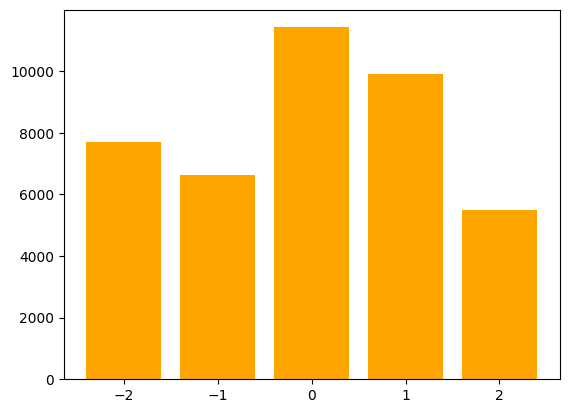

In [43]:
#TARGET COLUMN BARPLOT
xlab=df['Sentiment'].unique()
ylab=df['Sentiment'].value_counts()
plt.bar(xlab,ylab,color='orange')
plt.show()

In [44]:
#null value
print(df.isnull().sum())

OriginalTweet    0
Sentiment        0
dtype: int64


In [45]:
#defining text column to a variable
tweet=df['OriginalTweet']
tweet

,OriginalTweet
0,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...
1,advice Talk to your neighbours family to excha...
2,Coronavirus Australia: Woolworths to give elde...
3,My food stock is not the only one which is emp...
4,"Me, ready to go at supermarket during the #COV..."
...,...
41152,Airline pilots offering to stock supermarket s...
41153,Response to complaint not provided citing COVI...
41154,You know itÂs getting tough when @KameronWild...
41155,Is it wrong that the smell of hand sanitizer i...


In [46]:
#TOKENIZATION
nltk.download('punkt_tab')
from nltk.tokenize import TweetTokenizer
tk=TweetTokenizer()
tweet=tweet.apply(lambda x:tk.tokenize(x)).apply(lambda x:" ".join(x))
tweet

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


,OriginalTweet
0,@MeNyrbie @Phil_Gahan @Chrisitv https://t.co/i...
1,advice Talk to your neighbours family to excha...
2,Coronavirus Australia : Woolworths to give eld...
3,My food stock is not the only one which is emp...
4,"Me , ready to go at supermarket during the #CO..."
...,...
41152,Airline pilots offering to stock supermarket s...
41153,Response to complaint not provided citing COVI...
41154,You know itÂ  s getting tough when @KameronWi...
41155,Is it wrong that the smell of hand sanitizer i...


In [47]:
#REMOVING SPECIAL CHARACTERS
tweet=tweet.replace('[^a-zA-Z0-9]',' ',regex=True)
tweet

,OriginalTweet
0,MeNyrbie Phil Gahan Chrisitv https t co i...
1,advice Talk to your neighbours family to excha...
2,Coronavirus Australia Woolworths to give eld...
3,My food stock is not the only one which is emp...
4,Me ready to go at supermarket during the CO...
...,...
41152,Airline pilots offering to stock supermarket s...
41153,Response to complaint not provided citing COVI...
41154,You know it s getting tough when KameronWi...
41155,Is it wrong that the smell of hand sanitizer i...


In [48]:
#REMOVING WORDS LESS THAN 3 LETTERS
tweet=tweet.apply(lambda x:" ".join([i for i in tk.tokenize(x) if len(i)>=3]))
tweet

,OriginalTweet
0,MeNyrbie Phil Gahan Chrisitv https iFz 9FAn2Pa...
1,advice Talk your neighbours family exchange ph...
2,Coronavirus Australia Woolworths give elderly ...
3,food stock not the only one which empty PLEASE...
4,ready supermarket during the COVID outbreak No...
...,...
41152,Airline pilots offering stock supermarket shel...
41153,Response complaint not provided citing COVID r...
41154,You know getting tough when KameronWilds ratio...
41155,wrong that the smell hand sanitizer starting t...


In [49]:
#STEMMING AND STOPWORD REMOVAL
nltk.download('stopwords')
from nltk.stem import SnowballStemmer
from nltk.corpus import stopwords
ss=SnowballStemmer('english')
st=stopwords.words('english')
tweet=tweet.apply(lambda x:" ".join([ss.stem(i.lower()) for i in tk.tokenize(x) if i.lower() not in st]))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [50]:
#VECTORIZATION
from sklearn.feature_extraction.text import TfidfVectorizer
vec=TfidfVectorizer()
data=vec.fit_transform(tweet)
data

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 741754 stored elements and shape (41157, 74881)>

In [51]:
#input and output selection
x=data
y=df['Sentiment']
print(x.shape)

(41157, 74881)


In [52]:
#TRAIN TEST SPLITTING
from sklearn.model_selection import train_test_split
xtrain,xtest,ytrain,ytest=train_test_split(x,y,test_size=0.30,random_state=41)
print(xtrain.shape)
print(ytrain.shape)
print(xtest.shape)
print(ytest.shape)

(28809, 74881)
(28809,)
(12348, 74881)
(12348,)


In [53]:
#DATA BALANCING
print(ytrain.value_counts())
from imblearn.over_sampling import SMOTE
sm=SMOTE()
xtrain1,ytrain1=sm.fit_resample(xtrain,ytrain)
print(ytrain1.value_counts())

Sentiment
 1    8005
-1    6923
 0    5353
 2    4697
-2    3831
Name: count, dtype: int64
Sentiment
-1    8005
 2    8005
 0    8005
-2    8005
 1    8005
Name: count, dtype: int64


In [54]:
from sklearn.model_selection import GridSearchCV
#HYPERPARAMETER TUNING FOR KNN
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier()
knn_param={'n_neighbors':[5,7,9,11],'weights':['distance','random'],'metric':['euclidean','manhattan']}
knn_grid=GridSearchCV(knn_model,knn_param,cv=3,scoring='accuracy')
knn_grid.fit(xtrain1,ytrain1)
knn_grid.best_params_

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py:528: FitFailedWarning: 
24 fits failed out of a total of 48.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
24 fits failed with the following error:
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_validation.py", line 866, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
    ~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 1382, in wrapper
    estimator._validate_params()
    ~~~~~~~~~~~~~~~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/sklearn/base.py", line 436, in _validate_params
    validate_par

{'metric': 'euclidean', 'n_neighbors': 5, 'weights': 'distance'}

In [55]:
#KNN MODEL BUILDING
knn=KNeighborsClassifier(metric= 'euclidean', n_neighbors=5, weights='distance')
knn.fit(xtrain1,ytrain1)
knn_ypred=knn.predict(xtest)
knn_ypred

array([0, 0, 2, ..., 0, 0, 0])

In [56]:
#HYPERPARAMETER TUNING FOR NB
from sklearn.naive_bayes import BernoulliNB
nb_model=BernoulliNB()
nb_param={'alpha':[0.1,0.5,1.0,5.0],'binarize':[0.0,0.5,1.0],'fit_prior':[True,False]}
nb_grid=GridSearchCV(nb_model,nb_param,cv=3,scoring='accuracy')
nb_grid.fit(xtrain1,ytrain1)
nb_grid.best_params_

{'alpha': 0.1, 'binarize': 0.0, 'fit_prior': True}

In [57]:
#NB MODEL BUILDING
nb=BernoulliNB(alpha= 0.1, binarize= 0.0, fit_prior=True)
nb.fit(xtrain1,ytrain1)
nb_ypred=nb.predict(xtest)
nb_ypred

array([ 2, -1, -1, ..., -1,  1,  0])

In [60]:
#HYPERPARAMETER TUNING FOR DT
from sklearn.tree import DecisionTreeClassifier
dt_model=DecisionTreeClassifier(random_state=41)
dt_param={'criterion':['gini','entropy','log_loss'],'max_depth':[5,7,10,None],'min_samples_split':[2,5,10],
          'min_samples_leaf':[1,2,4]}
dt_grid=GridSearchCV(dt_model,dt_param,cv=3,scoring='accuracy')
dt_grid.fit(xtrain1,ytrain1)
dt_grid.best_params_

KeyboardInterrupt: 

In [ ]:
#DT MODEL BUILDING
dt=DecisionTreeClassifier(criterion= 'gini',max_depth= 7,min_samples_leaf= 1,min_samples_split=2,random_state=41)
dt.fit(xtrain1,ytrain1)
dt_ypred=dt.predict(xtest)
dt_ypred

In [ ]:
#HYPERPARAMETER TUNING FOR RFC
from sklearn.ensemble import RandomForestClassifier
rfc_model=RandomForestClassifier(random_state=41)
rfc_param={'n_estimators':[60,90,120],'max_depth':[5,10,15,None],'min_samples_split':[2,5,10],
          'min_samples_leaf':[1,2,4]}
rfc_grid=GridSearchCV(rfc_model,rfc_param,cv=3,scoring='accuracy')
rfc_grid.fit(xtrain1,ytrain1)
rfc_grid.best_params_

In [ ]:
#RFC MODEL BUILDING
rfc=RandomForestClassifier(n_estimators=60,max_depth= 10,min_samples_leaf= 1,min_samples_split=2,random_state=41)
rfc.fit(xtrain1,ytrain1)
rfc_ypred=rfc.predict(xtest)
rfc_ypred

In [ ]:
#HYPERPARAMETER TUNING FOR XGB
from xgboost import XGBClassifier
xgb_model=XGBClassifier(random_state=41)
xgb_param={'n_estimators':[60,90,120],'max_depth':[5,10,15,None],'learning_rate':[0.01,0.1],'subsample':[0.8,1.0]}
xgb_grid=GridSearchCV(xgb_model,xgb_param,cv=3,scoring='accuracy')
xgb_grid.fit(xtrain1,ytrain1)
xgb_grid.best_params_

In [ ]:
#XGB MODEL BUILDING
xgb=XGBClassifier(n_estimators=60,max_depth= 5,learning_rate=0.1,subsample=1.0,random_state=41)
xgb.fit(xtrain1,ytrain1)
xgb_ypred=xgb.predict(xtest)
xgb_ypred

In [ ]:
#HYPERPARAMETER TUNING FOR LR
from sklearn.linear_model import LogisticRegression
lr_model=LogisticRegression()
lr_param={'C':[0.01,0.1,1,10,100],'penalty':['l1','l2'],'solver':['liblinear']}
lr_grid=GridSearchCV(lr_model,lr_param,cv=3,scoring='accuracy')
lr_grid.fit(xtrain1,ytrain1)
lr_grid.best_params_

In [ ]:
#LR MODEL BUILDING
lr=LogisticRegression(C=0.1, penalty='l2',solver='liblinear')
lr.fit(xtrain1,ytrain1)
lr_ypred=lr.predict(xtest)
lr_ypred

In [ ]:
#TRAINING AND TESTING SCORE
print("KNN Training_score:",knn.score(xtrain1,ytrain1),"Testing_score:",knn.score(xtest,ytest))
print("NB Training_score:",nb.score(xtrain1,ytrain1),"Testing_score:",nb.score(xtest,ytest))
print("DT Training_score:",dt.score(xtrain1,ytrain1),"Testing_score:",dt.score(xtest,ytest))
print("RFC Training_score:",rfc.score(xtrain1,ytrain1),"Testing_score:",rfc.score(xtest,ytest))
print("XGB Training_score:",xgb.score(xtrain1,ytrain1),"Testing_score:",xgb.score(xtest,ytest))
print("LR Training_score:",lr.score(xtrain1,ytrain1),"Testing_score:",lr.score(xtest,ytest))

In [ ]:
#PERFORMANCE EVALUATION
from sklearn.metrics import accuracy_score
print("KNN accuracy_score:",accuracy_score(ytest,knn_ypred))
print("NB accuracy_score:",accuracy_score(ytest,nb_ypred))
print("DT accuracy_score:",accuracy_score(ytest,dt_ypred))
print("RFC accuracy_score:",accuracy_score(ytest,rfc_ypred))
print("XGB accuracy_score:",accuracy_score(ytest,xgb_ypred))
print("LR accuracy_score:",accuracy_score(ytest,lr_ypred))